# Thử nghiệm độ nhăn và độ dày thành ớt

Notebook này chỉ thử nghiệm trên quả đầu tiên của ảnh **029_IT250232_2.jpg** và không thay đổi pipeline runtime.

## Định nghĩa mask thành ớt

Thành ớt được tạo bởi phép trừ tất cả lớp con khỏi lớp chili:

\[
M_{wall}=M_{chili}\setminus(M_{endocarp}\cup M_{outer}\cup M_{placenta}\cup M_{seed})
\]

Mọi khoảng cách hình học được đổi sang mm bằng tỷ lệ QR (mm/pixel). Notebook dừng nếu không đọc được QR để tránh gắn nhãn pixel thành mm.

## Baseline hiện tại

**Độ dày:** mã hiện tại dùng distance transform trên mask thành ớt, lấy giá trị trên skeleton rồi nhân đôi:

\[
T_{old,avg}=\operatorname{mean}_{s\in skeleton}(2D(s))\times ratio
\]

Cách này giả định skeleton nằm chính giữa mép trong và mép ngoài.

**Độ nhăn:** contour ngoài lớn nhất của toàn bộ mask chili được xấp xỉ bằng approxPolyDP:

\[
W_{old}=1-\frac{P_{approx}}{P_{original}}
\]

Chỉ số này phụ thuộc epsilon, dùng toàn bộ chili thay vì riêng mép ngoài của thành ớt và không dùng một đơn vị đo vật lý cố định.

In [23]:
from pathlib import Path
import math
import warnings

import cv2
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import pandas as pd
from pyzbar.pyzbar import decode
from scipy.spatial import cKDTree
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from scipy import ndimage as ndi
from scipy.optimize import minimize_scalar
from skimage.morphology import skeletonize
import torch

from src.detect import DetectModel
from src.object import Chili
from src.segment import SegmentModel

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
BASE_DIR = Path("./")
IMAGE_PATH = BASE_DIR / "data" / "029_IT250232_2.jpg"
WEIGHT_PATH = BASE_DIR / "pretrain" / "yolov8_segment_v2.pt"
QR_SIZE_MM = 10.0
# Tham số hình học riêng của wrinkle: chord tối đa của một đoạn, theo mm.
# Không liên quan đến threshold kênh đỏ dùng khi tạo mask chili/detection.
WRINKLE_SEGMENT_THRESHOLD_MM = 5.0
THICKNESS_SAMPLE_SPACING_MM = 1.0
SKELETON_CLOSING_MM = 1.4
SKELETON_OPENING_MM = 0.6
DEVICE = 0 if torch.cuda.is_available() else "cpu"

assert IMAGE_PATH.exists(), IMAGE_PATH
assert WEIGHT_PATH.exists(), WEIGHT_PATH

def read_qr_ratio(path, qr_size_mm=QR_SIZE_MM):
    image = cv2.imread(str(path),4)
    if image is None:
        raise FileNotFoundError(path)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    codes = decode(gray)
    if not codes:
        raise RuntimeError("Không đọc được QR; dừng để không gắn nhãn pixel thành mm.")
    rect = codes[0].rect
    ratio = qr_size_mm / ((rect.width + rect.height) / 2.0)
    return ratio, codes

ratio, qr_codes = read_qr_ratio(IMAGE_PATH)
detector = DetectModel(model_name="none")
bboxes = detector.predict(str(IMAGE_PATH))
if not bboxes:
    raise RuntimeError("Không phát hiện được quả ớt.")
bboxes = sorted(bboxes, key=lambda box: box[0])

segmenter = SegmentModel(
    weight_path=str(WEIGHT_PATH),
    model_name="yolo",
    device=DEVICE,
)
chili = Chili(
    str(IMAGE_PATH),
    index=0,
    model_segment=segmenter,
    bbox=bboxes[0],
    ratio=ratio,
)

print(f"Ảnh: {IMAGE_PATH.name}")
print(f"Quả: 0 / {len(bboxes) - 1}")
print(f"QR tìm thấy: {len(qr_codes)}; ratio={ratio:.6f} mm/pixel")
print(f"Thiết bị: {DEVICE}")

Use threshold for detect each chili fruit

0: 544x640 23 seeds, 4 outers, 1 placenta, 1 endocarp, 1 chili, 608.2ms
Speed: 32.1ms preprocess, 608.2ms inference, 194.3ms postprocess per image at shape (1, 3, 544, 640)
Ảnh: 029_IT250232_2.jpg
Quả: 0 / 1
QR tìm thấy: 4; ratio=0.094787 mm/pixel
Thiết bị: cpu


## Độ dày mới

Boundary của thành ớt được gán là mép trong hoặc mép ngoài theo lớp ngữ nghĩa gần nhất. Skeleton chỉ định vị trí đo. Skeleton mới ưu tiên lấy từ wall đã closing/opening theo tham số mm, sau đó luôn giữ backbone geodesic dài nhất của mỗi component có nhánh. Component không có nhánh được giữ nguyên. Baseline vẫn dùng skeleton trực tiếp của wall gốc để bảo toàn cách tính cũ.

Skeleton được đổi thành các polyline có thứ tự và lấy mẫu theo arc length mỗi 1 mm. Điểm được nội suy dưới pixel; đường hở luôn giữ cả hai endpoint nên duy nhất khoảng cuối có thể ngắn hơn 1 mm. Tại mỗi điểm lấy mẫu, notebook quét các đường thẳng đi qua điểm đó. Mỗi đường phải cắt một mép trong và một mép ngoài ở hai hướng đối diện. Độ dày cục bộ là đường hợp lệ ngắn nhất. Các phép đo gần cuống/điểm nhánh hoặc lệch mạnh so với lân cận được loại khỏi thống kê; điểm lỗi hoặc bị lọc vẫn được vẽ màu xám.

Skeleton được xem là graph 8-neighbor có trọng số theo khoảng cách pixel. Tại mỗi vùng phân nhánh, đường chính được quyết định toàn cục bởi đường geodesic dài nhất giữa hai endpoint, thay vì chọn nhánh cục bộ. Đây là hậu xử lý duy nhất dùng cho phương pháp thickness mới.

In [24]:
def build_skeleton_graph(coords, shape):
    """Tạo graph 8-neighbor; bỏ cạnh chéo nếu đã có đường trực giao."""
    coords = np.asarray(coords, dtype=int)
    node_count = len(coords)
    index_image = np.full(shape, -1, dtype=np.int32)
    index_image[coords[:, 0], coords[:, 1]] = np.arange(node_count)
    rows, cols, weights = [], [], []
    for dy, dx in ((0, 1), (1, -1), (1, 0), (1, 1)):
        shifted_y = coords[:, 0] + dy
        shifted_x = coords[:, 1] + dx
        valid = (
            (shifted_y >= 0) & (shifted_y < shape[0])
            & (shifted_x >= 0) & (shifted_x < shape[1])
        )
        source = np.flatnonzero(valid)
        target = index_image[shifted_y[valid], shifted_x[valid]]
        connected = target >= 0
        source, target = source[connected], target[connected]
        if dy != 0 and dx != 0 and len(source):
            sy, sx = coords[source, 0], coords[source, 1]
            has_orthogonal = (index_image[sy, sx + dx] >= 0) | (index_image[sy + dy, sx] >= 0)
            source, target = source[~has_orthogonal], target[~has_orthogonal]
        edge_weight = math.hypot(dy, dx)
        rows.extend(source.tolist() + target.tolist())
        cols.extend(target.tolist() + source.tolist())
        weights.extend([edge_weight] * (2 * len(source)))
    return csr_matrix((weights, (rows, cols)), shape=(node_count, node_count))

def reconstruct_graph_path(predecessors, source, target):
    path = [int(target)]
    current = int(target)
    while current != int(source):
        current = int(predecessors[current])
        if current < 0:
            return []
        path.append(current)
    path.reverse()
    return path

def longest_backbone_skeleton(skeleton):
    """Phương án 2: giữ đường geodesic chính của từng component có nhánh.

    Skeleton được xem là graph 8-neighbor có trọng số 1 hoặc sqrt(2). Với
    component không phân nhánh, giữ nguyên để không phá đường thẳng/vòng tốt.
    Với component có nhánh, backbone là đường ngắn nhất dài nhất giữa hai
    endpoint. Đây là lựa chọn toàn cục, ổn định hơn chọn tham lam tại từng
    branch point. Component có nhánh luôn được rút về đúng một backbone.
    """
    skeleton = np.asarray(skeleton, dtype=bool)
    output = np.zeros_like(skeleton)
    labels, component_count = ndi.label(skeleton, structure=np.ones((3, 3), int))
    for component_id in range(1, component_count + 1):
        coords = np.argwhere(labels == component_id)
        node_count = len(coords)
        if node_count <= 2:
            output[coords[:, 0], coords[:, 1]] = True
            continue

        graph = build_skeleton_graph(coords, skeleton.shape)
        degree = np.diff(graph.indptr)
        endpoints = np.flatnonzero(degree == 1)
        branch_nodes = np.flatnonzero(degree >= 3)
        if len(branch_nodes) == 0:
            output[coords[:, 0], coords[:, 1]] = True
            continue
        if len(endpoints) < 2:
            seed_distances = dijkstra(graph, directed=False, indices=0)
            first = int(np.argmax(np.where(np.isfinite(seed_distances), seed_distances, -np.inf)))
            first_distances = dijkstra(graph, directed=False, indices=first)
            second = int(np.argmax(np.where(np.isfinite(first_distances), first_distances, -np.inf)))
            endpoints = np.array([first, second], dtype=int)

        distances, predecessors = dijkstra(
            graph, directed=False, indices=endpoints, return_predecessors=True
        )
        endpoint_distances = distances[:, endpoints]
        endpoint_distances[~np.isfinite(endpoint_distances)] = -np.inf
        source_pos, target_pos = np.unravel_index(
            np.argmax(endpoint_distances), endpoint_distances.shape
        )
        source_node = int(endpoints[source_pos])
        target_node = int(endpoints[target_pos])
        path = reconstruct_graph_path(predecessors[source_pos], source_node, target_node)
        if not path:
            raise RuntimeError(f"Không dựng được backbone cho component {component_id}.")
        path_coords = coords[np.asarray(path, dtype=int)]
        output[path_coords[:, 0], path_coords[:, 1]] = True

    return output

def smooth_wall_for_skeleton(
    wall, ratio, closing_mm=SKELETON_CLOSING_MM, opening_mm=SKELETON_OPENING_MM
):
    """Làm mượt wall CHỈ để chọn vị trí skeleton, không đụng wall/signed_distance
    dùng để đo. Biên răng cưa theo từng hạt khiến skeleton lượn sóng dù thành ớt
    thật trơn - closing rồi opening (bán kính quy theo mm/ratio) nối liền vết lõm
    cỡ hạt mà không xóa mất eo/túi thật của quả."""
    closing_radius_px = max(3, int(round(closing_mm / ratio)))
    opening_radius_px = max(2, int(round(opening_mm / ratio)))
    closed = ndi.binary_closing(wall, structure=np.ones((closing_radius_px, closing_radius_px)))
    smoothed = ndi.binary_opening(closed, structure=np.ones((opening_radius_px, opening_radius_px)))
    # Giữ mọi thành phần đủ lớn; chỉ giữ thành phần lớn nhất có thể làm mất
    # một nửa thành ớt khi mask bị ngắt tự nhiên tại vùng cuống.
    labels, count = ndi.label(smoothed)
    if count:
        sizes = ndi.sum(smoothed, labels, range(1, count + 1))
        keep = [i + 1 for i, size in enumerate(sizes) if size >= 30]
        smoothed = np.isin(labels, keep)
    return smoothed

def as_bool(mask):
    return np.asarray(mask) > 0

def build_wall_data(chili, ratio):
    chili_mask = as_bool(chili.mask_chili)
    endocarp = as_bool(chili.mask_endocarp)
    outer = as_bool(chili.mask_outer)
    placenta = as_bool(chili.mask_placenta)
    seed = as_bool(chili.mask_seed)
    stem = as_bool(chili.mask_stem)

    excluded = endocarp | outer | placenta | seed
    wall = chili_mask & ~excluded

    # Giữ cùng ngữ nghĩa phép trừ; chỉ bỏ các mảnh nhiễu rất nhỏ.
    labels, count = ndi.label(wall)
    if count:
        sizes = ndi.sum(wall, labels, range(1, count + 1))
        keep = [i + 1 for i, size in enumerate(sizes) if size >= 30]
        wall = np.isin(labels, keep)

    boundary = wall & ~ndi.binary_erosion(wall, structure=np.ones((3, 3)))
    inner_reference = endocarp | placenta | seed
    outer_reference = outer | ~chili_mask

    distance_to_inner = ndi.distance_transform_edt(~inner_reference)
    distance_to_outer = ndi.distance_transform_edt(~outer_reference)
    inner_edge = boundary & (distance_to_inner <= distance_to_outer)
    outer_edge = boundary & (distance_to_outer < distance_to_inner)
    # Loại vùng cuống trước khi tạo các đoạn wrinkle. Dilation 2 px chỉ
    # đóng vai trò dung sai raster, không phải threshold độ nhăn.
    stem_exclusion = ndi.binary_dilation(stem, structure=np.ones((3, 3)), iterations=2)
    wrinkle_outer_edge = outer_edge & ~stem_exclusion
    stem_edge_excluded = outer_edge & stem_exclusion

    inside_distance = ndi.distance_transform_edt(wall)
    outside_distance = ndi.distance_transform_edt(~wall)
    signed_distance = inside_distance - outside_distance
    # Bản mượt chỉ dùng để CHỌN VỊ TRÍ lát cắt; ray-casting bên dưới vẫn
    # đo trên signed_distance của wall gốc. Nếu smoothing làm mất quá nhiều
    # cấu trúc thì tự động quay về wall gốc.
    wall_for_skeleton = smooth_wall_for_skeleton(wall, ratio)
    raw_skeleton = skeletonize(wall)
    smoothed_skeleton = skeletonize(wall_for_skeleton)
    minimum_skeleton_pixels = max(20, int(0.50 * np.count_nonzero(raw_skeleton)))
    use_smoothed = np.count_nonzero(smoothed_skeleton) >= minimum_skeleton_pixels
    skeleton_before_backbone = smoothed_skeleton if use_smoothed else raw_skeleton
    skeleton = longest_backbone_skeleton(skeleton_before_backbone)
    measurement_skeleton = skeleton & wall
    # Skeleton có thể đi qua vùng nhỏ vừa được closing lấp. Chỉ pixel còn
    # trong wall thật được lấy làm tâm đo; nếu quá ít thì quay về wall gốc.
    if np.count_nonzero(measurement_skeleton) < 20:
        skeleton_before_backbone = raw_skeleton
        skeleton = longest_backbone_skeleton(raw_skeleton)
        measurement_skeleton = skeleton
        use_smoothed = False
        backbone_mode = "fallback_raw_wall"
    else:
        backbone_mode = "longest_geodesic"
    backbone_retain_ratio = (
        np.count_nonzero(skeleton) / max(1, np.count_nonzero(skeleton_before_backbone))
    )

    return {
        "wall": wall,
        "boundary": boundary,
        "inner_reference": inner_reference,
        "outer_reference": outer_reference,
        "distance_to_inner": distance_to_inner,
        "distance_to_outer": distance_to_outer,
        "inner_edge": inner_edge,
        "outer_edge": outer_edge,
        "stem_exclusion": stem_exclusion,
        "wrinkle_outer_edge": wrinkle_outer_edge,
        "stem_edge_excluded": stem_edge_excluded,
        "signed_distance": signed_distance,
        "wall_for_skeleton": wall_for_skeleton,
        "skeleton": skeleton,
        "measurement_skeleton": measurement_skeleton,
        "skeleton_before_backbone": skeleton_before_backbone,
        "backbone_removed": skeleton_before_backbone & ~skeleton,
        "backbone_retain_ratio": backbone_retain_ratio,
        "skeleton_source": "smoothed_wall" if use_smoothed else "raw_wall",
        "skeleton_postprocess": backbone_mode,
    }

def bilinear_many(array, x, y, outside_value=-1.0):
    x, y = np.asarray(x, float), np.asarray(y, float)
    result = np.full(np.broadcast(x, y).shape, float(outside_value))
    h, w = array.shape
    valid = (x >= 0) & (y >= 0) & (x <= w - 1) & (y <= h - 1)
    if not np.any(valid):
        return result
    xv, yv = x[valid], y[valid]
    x0, y0 = np.floor(xv).astype(int), np.floor(yv).astype(int)
    x1, y1 = np.minimum(x0 + 1, w - 1), np.minimum(y0 + 1, h - 1)
    dx, dy = xv - x0, yv - y0
    result[valid] = (
        array[y0, x0] * (1-dx) * (1-dy)
        + array[y0, x1] * dx * (1-dy)
        + array[y1, x0] * (1-dx) * dy
        + array[y1, x1] * dx * dy
    )
    return result

def bilinear(array, x, y, outside_value=-1.0):
    return float(bilinear_many(array, np.array([x]), np.array([y]), outside_value)[0])

def ray_exits(center_xy, directions, signed_distance):
    """Quét đồng thời nhiều tia rồi nội suy nghiệm signed_distance=0."""
    directions = np.asarray(directions, float)
    count = len(directions)
    h, w = signed_distance.shape
    max_distance = float(np.hypot(h, w))
    distances = np.zeros(count)
    values = np.full(count, bilinear(signed_distance, center_xy[0], center_xy[1]))
    active = values > 0
    low, high = np.full(count, np.nan), np.full(count, np.nan)
    for _ in range(int(max_distance / 0.35) + 2):
        if not np.any(active):
            break
        ids = np.flatnonzero(active)
        steps = np.clip(values[ids] * 0.65, 0.35, 3.0)
        next_distances = np.minimum(max_distance, distances[ids] + steps)
        points = np.asarray(center_xy) + next_distances[:, None] * directions[ids]
        next_values = bilinear_many(signed_distance, points[:, 0], points[:, 1])
        hit = next_values <= 0
        hit_ids = ids[hit]
        low[hit_ids], high[hit_ids] = distances[hit_ids], next_distances[hit]
        active[hit_ids] = False
        remaining = ids[~hit]
        distances[remaining] = next_distances[~hit]
        values[remaining] = next_values[~hit]
        active[remaining[distances[remaining] >= max_distance]] = False
    valid = np.isfinite(low)
    roots = np.full(count, np.nan)
    if np.any(valid):
        ids = np.flatnonzero(valid)
        lo, hi = low[ids].copy(), high[ids].copy()
        for _ in range(14):
            mid = (lo + hi) / 2
            points = np.asarray(center_xy) + mid[:, None] * directions[ids]
            mid_values = bilinear_many(signed_distance, points[:, 0], points[:, 1])
            inside = mid_values > 0
            lo[inside], hi[~inside] = mid[inside], mid[~inside]
        roots[ids] = (lo + hi) / 2
    points = np.asarray(center_xy) + roots[:, None] * directions
    return points, roots, valid

def sections_for_angles(center_xy, angles, wall_data):
    angles = np.asarray(angles, float)
    radians = np.deg2rad(angles)
    directions = np.column_stack([np.cos(radians), np.sin(radians)])
    p_pos, r_pos, ok_pos = ray_exits(center_xy, directions, wall_data["signed_distance"])
    p_neg, r_neg, ok_neg = ray_exits(center_xy, -directions, wall_data["signed_distance"])
    valid = ok_pos & ok_neg
    pos_inner = bilinear_many(wall_data["distance_to_inner"], p_pos[:,0], p_pos[:,1], np.inf) <= bilinear_many(wall_data["distance_to_outer"], p_pos[:,0], p_pos[:,1], np.inf)
    neg_inner = bilinear_many(wall_data["distance_to_inner"], p_neg[:,0], p_neg[:,1], np.inf) <= bilinear_many(wall_data["distance_to_outer"], p_neg[:,0], p_neg[:,1], np.inf)
    valid &= pos_inner != neg_inner
    output = []
    for i in np.flatnonzero(valid):
        inner, outer = (p_pos[i], p_neg[i]) if pos_inner[i] else (p_neg[i], p_pos[i])
        output.append({"inner": inner, "outer": outer, "length_px": float(r_pos[i] + r_neg[i]), "angle_deg": float(angles[i] % 180)})
    return output

def measure_skeleton_point(center_xy, wall_data):
    coarse = sections_for_angles(center_xy, np.arange(0.0, 180.0, 1.0), wall_data)
    if not coarse:
        return None
    best = min(coarse, key=lambda item: item["length_px"])
    fine_angles = np.arange(best["angle_deg"] - 1.0, best["angle_deg"] + 1.0001, 0.1)
    refined = sections_for_angles(center_xy, fine_angles, wall_data)
    return min(refined or [best], key=lambda item: item["length_px"])

def ordered_skeleton_paths(skeleton):
    """Đổi từng component không nhánh thành polyline có thứ tự."""
    skeleton = np.asarray(skeleton, dtype=bool)
    labels, component_count = ndi.label(skeleton, structure=np.ones((3, 3), int))
    paths = []
    for component_id in range(1, component_count + 1):
        coords = np.argwhere(labels == component_id)
        if len(coords) == 1:
            paths.append({"component_id": component_id, "points_xy": coords[:, ::-1].astype(float), "closed": False})
            continue
        graph = build_skeleton_graph(coords, skeleton.shape)
        degree = np.diff(graph.indptr)
        endpoints = np.flatnonzero(degree == 1)
        closed = len(endpoints) == 0 and np.all(degree == 2)

        if closed:
            start = 0  # np.argwhere đã sắp theo y rồi x: điểm trên-trái
            path, visited = [start], {start}
            previous, current = -1, start
            while True:
                neighbors = graph.indices[graph.indptr[current]:graph.indptr[current + 1]]
                candidates = [int(node) for node in neighbors if int(node) != previous]
                if previous < 0:
                    candidates.sort(key=lambda node: (coords[node, 0], coords[node, 1]))
                next_node = next((node for node in candidates if node not in visited), start)
                if next_node == start:
                    break
                path.append(next_node)
                visited.add(next_node)
                previous, current = current, next_node
            if len(path) != len(coords):
                raise RuntimeError(f"Không sắp được cycle skeleton {component_id}.")
        else:
            if len(endpoints) < 2:
                seed_distance = dijkstra(graph, directed=False, indices=0)
                source = int(np.argmax(np.where(np.isfinite(seed_distance), seed_distance, -np.inf)))
            else:
                source = min(endpoints, key=lambda node: (coords[node, 0], coords[node, 1]))
            distances, predecessors = dijkstra(
                graph, directed=False, indices=int(source), return_predecessors=True
            )
            target_candidates = endpoints if len(endpoints) >= 2 else np.arange(len(coords))
            target = int(target_candidates[np.argmax(distances[target_candidates])])
            path = reconstruct_graph_path(predecessors, source, target)
            if not path:
                raise RuntimeError(f"Không sắp được skeleton component {component_id}.")

        paths.append({
            "component_id": component_id,
            "points_xy": coords[np.asarray(path, dtype=int)][:, ::-1].astype(float),
            "closed": closed,
        })
    return paths

def sample_skeleton_at_spacing(skeleton, ratio, spacing_mm=THICKNESS_SAMPLE_SPACING_MM):
    """Nội suy điểm theo arc length; giữ hai endpoint của đường hở."""
    spacing_px = spacing_mm / ratio
    rows, sample_id = [], 0
    for path_info in ordered_skeleton_paths(skeleton):
        points = path_info["points_xy"]
        closed = path_info["closed"]
        interpolation_points = np.vstack([points, points[0]]) if closed else points
        lengths = np.linalg.norm(np.diff(interpolation_points, axis=0), axis=1)
        cumulative = np.concatenate([[0.0], np.cumsum(lengths)])
        total_px = float(cumulative[-1])
        if total_px <= 1e-9:
            positions = np.array([0.0])
        elif closed:
            positions = np.arange(0.0, total_px - 1e-9, spacing_px)
        else:
            positions = np.arange(0.0, total_px + 1e-9, spacing_px)
            if total_px - positions[-1] > 1e-9:
                positions = np.append(positions, total_px)

        for local_index, position in enumerate(positions):
            segment_index = min(np.searchsorted(cumulative, position, side="right") - 1, len(lengths) - 1)
            if len(lengths) == 0:
                point = points[0]
            else:
                segment_length = max(lengths[segment_index], 1e-12)
                alpha = (position - cumulative[segment_index]) / segment_length
                point = interpolation_points[segment_index] + alpha * (interpolation_points[segment_index + 1] - interpolation_points[segment_index])
            if local_index == 0:
                previous_gap_mm = (total_px - positions[-1]) * ratio if closed else np.nan
                is_tail_gap = bool(closed and previous_gap_mm < spacing_mm - 1e-9)
            else:
                previous_gap_mm = (positions[local_index] - positions[local_index - 1]) * ratio
                is_tail_gap = bool((not closed) and local_index == len(positions) - 1 and previous_gap_mm < spacing_mm - 1e-9)
            rows.append({
                "sample_id": sample_id,
                "component_id": path_info["component_id"],
                "sample_index": local_index,
                "path_position_mm": position * ratio,
                "skeleton_x": float(point[0]),
                "skeleton_y": float(point[1]),
                "is_endpoint": bool((not closed) and local_index in (0, len(positions) - 1)),
                "is_closed_component": bool(closed),
                "previous_gap_mm": previous_gap_mm,
                "is_tail_gap": is_tail_gap,
            })
            sample_id += 1
    return pd.DataFrame(rows)

def measure_new_thickness(wall_data, ratio, progress_every=250):
    samples = sample_skeleton_at_spacing(wall_data["measurement_skeleton"], ratio)
    rows = []
    for index, sample in samples.iterrows():
        row = sample.to_dict()
        result = measure_skeleton_point((sample.skeleton_x, sample.skeleton_y), wall_data)
        if result is None:
            row.update({"measurement_status": "ray_failed"})
        else:
            row.update({
                "inner_x": result["inner"][0], "inner_y": result["inner"][1],
                "outer_x": result["outer"][0], "outer_y": result["outer"][1],
                "angle_deg": result["angle_deg"],
                "thickness_px": result["length_px"],
                "thickness_mm": result["length_px"] * ratio,
                "measurement_status": "measured",
            })
        rows.append(row)
        if progress_every and (index + 1) % progress_every == 0:
            print(f"Đã đo {index + 1}/{len(samples)} điểm skeleton")
    result_df = pd.DataFrame(rows)
    valid_count = int((result_df.measurement_status == "measured").sum()) if len(result_df) else 0
    coverage = valid_count / len(result_df) if len(result_df) else 0.0
    regular_gaps = result_df.loc[result_df.previous_gap_mm.notna() & ~result_df.is_tail_gap, "previous_gap_mm"]
    spacing_error = float(np.max(np.abs(regular_gaps - THICKNESS_SAMPLE_SPACING_MM))) if len(regular_gaps) else 0.0
    return result_df, coverage, np.count_nonzero(wall_data["measurement_skeleton"]), spacing_error

def baseline_thickness(wall, ratio):
    distance = cv2.distanceTransform(
        wall.astype(np.uint8), cv2.DIST_L2, 5
    )
    # Baseline phải giữ đúng phương pháp cũ để phép so sánh không bị lẫn
    # ảnh hưởng của smoothing, backbone hay bộ lọc mới.
    skeleton = skeletonize(wall)
    values = distance[skeleton]
    return {
        "avg_mm": float(np.mean(2.0 * values) * ratio) if len(values) else np.nan,
        "max_mm": float(np.max(distance) * 2.0 * ratio) if distance.size else np.nan,
        "distance": distance,
        "skeleton": skeleton,
    }

wall_data = build_wall_data(chili, ratio)
baseline_t = baseline_thickness(wall_data["wall"], ratio)
thickness_samples, thickness_coverage, skeleton_pixel_count, spacing_error_max_mm = measure_new_thickness(
    wall_data, ratio
)
thickness_points = thickness_samples[
    thickness_samples.measurement_status == "measured"
].copy().reset_index(drop=True)
if thickness_points.empty:
    raise RuntimeError("Không tìm được lát cắt độ dày hợp lệ.")

thickness_raw_summary = {
    "baseline_avg_mm": baseline_t["avg_mm"],
    "baseline_max_mm": baseline_t["max_mm"],
    "new_raw_mean_mm": thickness_points["thickness_mm"].mean(),
    "new_raw_median_mm": thickness_points["thickness_mm"].median(),
    "new_raw_min_mm": thickness_points["thickness_mm"].min(),
    "new_raw_max_mm": thickness_points["thickness_mm"].max(),
    "new_raw_std_mm": thickness_points["thickness_mm"].std(ddof=0),
    "raw_valid_points": len(thickness_points),
    "sample_spacing_mm": THICKNESS_SAMPLE_SPACING_MM,
    "requested_sample_points": len(thickness_samples),
    "ray_failed_points": int((thickness_samples.measurement_status == "ray_failed").sum()),
    "skeleton_pixel_count": skeleton_pixel_count,
    "coverage": thickness_coverage,
    "spacing_error_max_mm": spacing_error_max_mm,
    "skeleton_source": wall_data["skeleton_source"],
    "skeleton_postprocess": wall_data["skeleton_postprocess"],
    "retain_ratio": wall_data["backbone_retain_ratio"],
}
display(pd.DataFrame([thickness_raw_summary]))

Đã đo 250/422 điểm skeleton


,baseline_avg_mm,baseline_max_mm,new_raw_mean_mm,new_raw_median_mm,new_raw_min_mm,new_raw_max_mm,new_raw_std_mm,raw_valid_points,sample_spacing_mm,requested_sample_points,ray_failed_points,skeleton_pixel_count,coverage,spacing_error_max_mm,skeleton_source,skeleton_postprocess,retain_ratio
0,3.74548,11.586615,6.671866,6.142341,0.543688,16.288321,2.422719,368,1.0,422,54,3527,0.872038,2.597922e-14,smoothed_wall,longest_geodesic,0.932394


## Độ nhăn mới

Chỉ các run thuộc **mép ngoài thật của vùng wall màu cam** mới được sử dụng. Các điểm nằm trong vùng cuống được loại trước khi chia đoạn, vì vậy đường đóng nhân tạo đi qua cuống không tham gia tính wrinkle.

`WRINKLE_SEGMENT_THRESHOLD_MM` là tham số hình học có thể thay đổi (giá trị đang thử nghiệm: 5 mm). Nó quy định chord tối đa của mỗi đoạn và hoàn toàn độc lập với threshold kênh đỏ dùng cho detection/tạo mask chili. Mỗi biên cắt được tìm bằng giao điểm chính xác giữa contour và đường tròn có bán kính bằng tham số này, nên không phụ thuộc các vertex có sẵn.

Với mỗi đoạn:

\[
K_i=\frac{arc_i}{chord_i},\qquad E_i=K_i-1
\]

Chỉ số wrinkle mới là trung bình độ cong dư:

\[
W_{new}=\frac{1}{N}\sum_i E_i
\]

Nếu còn một đoạn ngắn ở cuối, biên giữa hai đoạn cuối được tìm lại để hai chord gần bằng nhau và đều không vượt quá `WRINKLE_SEGMENT_THRESHOLD_MM`.

In [25]:
def smooth_circular_labels(labels, window=7):
    labels = np.asarray(labels, dtype=np.uint8)
    if len(labels) < window:
        return labels.astype(bool)
    radius = window // 2
    padded = np.concatenate([labels[-radius:], labels, labels[:radius]])
    votes = np.convolve(padded, np.ones(window, dtype=int), mode="valid")
    return votes >= (window // 2 + 1)

def split_true_runs(points, selected, closed):
    points = np.asarray(points, dtype=float)
    selected = np.asarray(selected, dtype=bool)
    if not np.any(selected):
        return []
    if np.all(selected):
        run = np.vstack([points, points[0]]) if closed else points
        return [run]

    # Với contour kín, bắt đầu ngay sau một điểm false để nối đúng run qua index 0.
    if closed:
        false_index = int(np.flatnonzero(~selected)[0])
        order = np.r_[np.arange(false_index + 1, len(points)), np.arange(0, false_index + 1)]
        points = points[order]
        selected = selected[order]

    runs, current = [], []
    for point, keep in zip(points, selected):
        if keep:
            current.append(point)
        elif current:
            if len(current) >= 2:
                runs.append(np.asarray(current, dtype=float))
            current = []
    if len(current) >= 2:
        runs.append(np.asarray(current, dtype=float))
    return runs

def extract_outer_edge_runs(wall_data, minimum_arc_px=5.0):
    wall_u8 = wall_data["wall"].astype(np.uint8) * 255
    contours, hierarchy = cv2.findContours(
        wall_u8, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE
    )
    runs = []
    for contour in contours:
        points = contour[:, 0, :].astype(float)
        if len(points) < 3:
            continue
        labels = []
        outside_stem_flags = []
        for x, y in points:
            d_inner = bilinear(wall_data["distance_to_inner"], x, y, np.inf)
            d_outer = bilinear(wall_data["distance_to_outer"], x, y, np.inf)
            yi = int(np.clip(round(y), 0, wall_data["wall"].shape[0] - 1))
            xi = int(np.clip(round(x), 0, wall_data["wall"].shape[1] - 1))
            outside_stem = not wall_data["stem_exclusion"][yi, xi]
            labels.append(d_outer < d_inner)
            outside_stem_flags.append(outside_stem)
        labels = smooth_circular_labels(labels, window=7)
        # Áp vùng cấm sau bước majority smoothing để không nối kín qua cuống.
        labels &= np.asarray(outside_stem_flags, dtype=bool)
        for run in split_true_runs(points, labels, closed=True):
            arc = np.linalg.norm(np.diff(run, axis=0), axis=1).sum()
            if arc >= minimum_arc_px:
                runs.append(run)
    return sorted(
        runs,
        key=lambda run: np.linalg.norm(np.diff(run, axis=0), axis=1).sum(),
        reverse=True,
    )

def polyline_geometry(points):
    points = np.asarray(points, dtype=float)
    segment_lengths = np.linalg.norm(np.diff(points, axis=0), axis=1)
    keep = np.r_[True, segment_lengths > 1e-12]
    points = points[keep]
    segment_lengths = np.linalg.norm(np.diff(points, axis=0), axis=1)
    cumulative = np.r_[0.0, np.cumsum(segment_lengths)]
    return points, cumulative

def point_at_arc(points, cumulative, arc_position):
    s = float(np.clip(arc_position, 0.0, cumulative[-1]))
    if s >= cumulative[-1]:
        return points[-1].copy()
    index = int(np.searchsorted(cumulative, s, side="right") - 1)
    index = min(max(index, 0), len(points) - 2)
    length = cumulative[index + 1] - cumulative[index]
    alpha = 0.0 if length <= 1e-12 else (s - cumulative[index]) / length
    return points[index] + alpha * (points[index + 1] - points[index])

def first_circle_intersection(points, cumulative, start_s, radius):
    """Giao đầu tiên theo chiều contour với đường tròn tâm tại start_s."""
    center = point_at_arc(points, cumulative, start_s)
    index = int(np.searchsorted(cumulative, start_s, side="right") - 1)
    index = min(max(index, 0), len(points) - 2)

    for segment_index in range(index, len(points) - 1):
        a = (
            point_at_arc(points, cumulative, start_s)
            if segment_index == index
            else points[segment_index]
        )
        a_s = start_s if segment_index == index else cumulative[segment_index]
        b = points[segment_index + 1]
        vector = b - a
        aa = float(np.dot(vector, vector))
        if aa <= 1e-12:
            continue
        relative = a - center
        bb = 2.0 * float(np.dot(relative, vector))
        cc = float(np.dot(relative, relative) - radius * radius)
        discriminant = bb * bb - 4.0 * aa * cc
        if discriminant < 0:
            continue
        sqrt_disc = math.sqrt(max(0.0, discriminant))
        roots = sorted(((-bb - sqrt_disc) / (2.0 * aa), (-bb + sqrt_disc) / (2.0 * aa)))
        for root in roots:
            if -1e-10 <= root <= 1.0 + 1e-10:
                root = float(np.clip(root, 0.0, 1.0))
                candidate_s = a_s + root * math.sqrt(aa)
                if candidate_s > start_s + 1e-8:
                    return candidate_s
    return None

def balanced_tail_split(points, cumulative, start_s, end_s, radius):
    """Chia vùng cuối sao cho hai chord gần bằng nhau và không vượt radius."""
    start = point_at_arc(points, cumulative, start_s)
    end = point_at_arc(points, cumulative, end_s)
    margin = max(1e-7, (end_s - start_s) * 1e-6)

    def objective(split_s):
        split = point_at_arc(points, cumulative, split_s)
        first = np.linalg.norm(split - start)
        second = np.linalg.norm(end - split)
        overflow = max(0.0, first - radius) + max(0.0, second - radius)
        return abs(first - second) + 1000.0 * overflow

    result = minimize_scalar(
        objective,
        bounds=(start_s + margin, end_s - margin),
        method="bounded",
        options={"xatol": 1e-7},
    )
    split_s = float(result.x)
    split = point_at_arc(points, cumulative, split_s)
    chords = (np.linalg.norm(split - start), np.linalg.norm(end - split))
    if max(chords) > radius + 1e-4:
        # Fallback quyết định trên lưới nếu objective liên tục rơi vào cực tiểu xấu.
        grid = np.linspace(start_s + margin, end_s - margin, 2001)
        candidates = []
        for value in grid:
            p = point_at_arc(points, cumulative, value)
            c1, c2 = np.linalg.norm(p - start), np.linalg.norm(end - p)
            if c1 <= radius + 1e-6 and c2 <= radius + 1e-6:
                candidates.append((abs(c1 - c2), value))
        if candidates:
            split_s = min(candidates)[1]
    return split_s

def segment_polyline_by_exact_chord(points, chord_px):
    points, cumulative = polyline_geometry(points)
    total = cumulative[-1]
    if total <= 1e-10:
        return points, cumulative, []

    cuts = [0.0]
    while True:
        next_s = first_circle_intersection(points, cumulative, cuts[-1], chord_px)
        if next_s is None or total - next_s <= 1e-8:
            break
        cuts.append(next_s)

    if len(cuts) == 1:
        cuts.append(total)
    else:
        remainder_exists = total - cuts[-1] > 1e-8
        if remainder_exists:
            previous_start = cuts[-2] if len(cuts) >= 2 else 0.0
            split_s = balanced_tail_split(
                points, cumulative, previous_start, total, chord_px
            )
            cuts = cuts[:-1] + [split_s, total]
        elif cuts[-1] < total:
            cuts.append(total)

    if cuts[-1] < total - 1e-8:
        cuts.append(total)

    segments = []
    for start_s, end_s in zip(cuts[:-1], cuts[1:]):
        p0 = point_at_arc(points, cumulative, start_s)
        p1 = point_at_arc(points, cumulative, end_s)
        chord = float(np.linalg.norm(p1 - p0))
        arc = float(end_s - start_s)
        if chord <= 1e-10:
            continue
        segments.append({
            "start_s": start_s,
            "end_s": end_s,
            "start": p0,
            "end": p1,
            "arc_px": arc,
            "chord_px": chord,
            "curvature_ratio": arc / chord,
            "curvature_excess": arc / chord - 1.0,
        })
    return points, cumulative, segments

def slice_polyline(points, cumulative, start_s, end_s):
    start = point_at_arc(points, cumulative, start_s)
    end = point_at_arc(points, cumulative, end_s)
    inside = (cumulative > start_s) & (cumulative < end_s)
    return np.vstack([start, points[inside], end])

def baseline_wrinkle(mask_chili, epsilon_factor=0.005):
    contours, _ = cv2.findContours(
        mask_chili.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    if not contours:
        return np.nan
    contour = max(contours, key=cv2.contourArea)
    perimeter = cv2.arcLength(contour, True)
    approximation = cv2.approxPolyDP(contour, epsilon_factor * perimeter, True)
    return 1.0 - cv2.arcLength(approximation, True) / perimeter

def calculate_new_wrinkle(outer_runs, ratio, wrinkle_threshold_mm=WRINKLE_SEGMENT_THRESHOLD_MM):
    chord_px = wrinkle_threshold_mm / ratio
    rows, run_geometries = [], []
    for run_id, run in enumerate(outer_runs):
        points, cumulative, segments = segment_polyline_by_exact_chord(run, chord_px)
        run_geometries.append((points, cumulative, segments))
        for segment_id, segment in enumerate(segments):
            rows.append({
                "run_id": run_id,
                "segment_id": segment_id,
                "start_x": segment["start"][0],
                "start_y": segment["start"][1],
                "end_x": segment["end"][0],
                "end_y": segment["end"][1],
                "arc_mm": segment["arc_px"] * ratio,
                "chord_mm": segment["chord_px"] * ratio,
                "curvature_ratio": segment["curvature_ratio"],
                "curvature_excess": segment["curvature_excess"],
            })
    return pd.DataFrame(rows), run_geometries

outer_runs = extract_outer_edge_runs(wall_data)
wrinkle_segments, wrinkle_geometries = calculate_new_wrinkle(outer_runs, ratio)
if wrinkle_segments.empty:
    raise RuntimeError("Không tách được đoạn wrinkle trên mép ngoài.")

wrinkle_summary = {
    "baseline_wrinkle": baseline_wrinkle(chili.mask_chili),
    "new_wrinkle_mean_excess": wrinkle_segments["curvature_excess"].mean(),
    "mean_curvature_ratio": wrinkle_segments["curvature_ratio"].mean(),
    "segment_count": len(wrinkle_segments),
    "outer_run_count": len(outer_runs),
    "outer_arc_total_mm": wrinkle_segments["arc_mm"].sum(),
    "wrinkle_segment_threshold_mm": WRINKLE_SEGMENT_THRESHOLD_MM,
    "max_chord_mm": wrinkle_segments["chord_mm"].max(),
}
pd.DataFrame([wrinkle_summary])

,baseline_wrinkle,new_wrinkle_mean_excess,mean_curvature_ratio,segment_count,outer_run_count,outer_arc_total_mm,wrinkle_segment_threshold_mm,max_chord_mm
0,0.066527,0.131135,1.131135,74,6,401.592273,5.0,5.0


In [26]:
# Synthetic tests
straight = np.column_stack([np.linspace(0, 100, 101), np.zeros(101)])
_, _, straight_segments = segment_polyline_by_exact_chord(straight, 20.0)
straight_wrinkle = np.mean([s["curvature_excess"] for s in straight_segments])
assert abs(straight_wrinkle) < 1e-10

zigzag = np.array([
    [0, 0], [10, 7], [20, 0], [30, 7], [40, 0],
    [50, 7], [60, 0], [70, 7], [80, 0],
], dtype=float)
_, _, zigzag_segments = segment_polyline_by_exact_chord(zigzag, 20.0)
zigzag_wrinkle = np.mean([s["curvature_excess"] for s in zigzag_segments])
assert zigzag_wrinkle > straight_wrinkle

# Dải raster từ -5 đến +5 có độ dày biên-đến-biên là 11 px.
def synthetic_wall(angle_deg=0.0):
    size = 121
    yy, xx = np.mgrid[:size, :size]
    angle = np.deg2rad(angle_deg)
    normal = np.array([-np.sin(angle), np.cos(angle)])
    signed_normal = (xx - 60) * normal[0] + (yy - 60) * normal[1]
    wall = np.abs(signed_normal) <= 5.0
    inner_ref = signed_normal < -5.0
    outer_ref = signed_normal > 5.0
    data = {
        "wall": wall,
        "distance_to_inner": ndi.distance_transform_edt(~inner_ref),
        "distance_to_outer": ndi.distance_transform_edt(~outer_ref),
        "signed_distance": ndi.distance_transform_edt(wall) - ndi.distance_transform_edt(~wall),
    }
    return data

for angle, expected_px in ((0.0, 11.0), (27.0, 10.0)):
    data = synthetic_wall(angle)
    result = measure_skeleton_point((60.0, 60.0), data)
    assert result is not None
    assert abs(result["length_px"] - expected_px) <= 0.3, (angle, result["length_px"])

# Skeleton chữ T: backbone phải giữ trục ngang dài và loại nhánh dọc ngắn.
t_skeleton = np.zeros((101, 101), dtype=bool)
t_skeleton[50, 10:91] = True
t_skeleton[50:71, 50] = True
t_backbone = longest_backbone_skeleton(t_skeleton)
assert np.count_nonzero(t_backbone[50, 10:91]) >= 79
assert np.count_nonzero(t_backbone[52:71, 50]) == 0

# Lấy mẫu dọc skeleton: khoảng thường đúng 1 mm, giữ endpoint và phần dư cuối.
horizontal_skeleton = np.zeros((20, 50), dtype=bool)
horizontal_skeleton[10, 10:36] = True  # chiều dài endpoint-endpoint = 25 px = 2,5 mm
horizontal_samples = sample_skeleton_at_spacing(horizontal_skeleton, ratio=0.1, spacing_mm=1.0)
assert np.allclose(horizontal_samples.previous_gap_mm.dropna().to_numpy(), [1.0, 1.0, 0.5], atol=1e-10)
assert horizontal_samples.is_endpoint.sum() == 2
assert horizontal_samples.iloc[-1].is_tail_gap

short_skeleton = np.zeros((10, 10), dtype=bool)
short_skeleton[5, 2:7] = True  # 0,4 mm
short_samples = sample_skeleton_at_spacing(short_skeleton, ratio=0.1, spacing_mm=1.0)
assert len(short_samples) == 2 and short_samples.is_endpoint.all()
assert np.isclose(short_samples.iloc[-1].previous_gap_mm, 0.4)

diagonal_skeleton = np.zeros((40, 40), dtype=bool)
np.fill_diagonal(diagonal_skeleton[5:26, 5:26], True)
diagonal_samples = sample_skeleton_at_spacing(diagonal_skeleton, ratio=0.05, spacing_mm=1.0)
regular_diagonal = diagonal_samples.loc[
    diagonal_samples.previous_gap_mm.notna() & ~diagonal_samples.is_tail_gap, "previous_gap_mm"
]
assert np.allclose(regular_diagonal, 1.0, atol=0.01)

multi_skeleton = horizontal_skeleton.copy()
multi_skeleton[2, 2:8] = True
multi_samples = sample_skeleton_at_spacing(multi_skeleton, ratio=0.1, spacing_mm=1.0)
assert multi_samples.component_id.nunique() == 2

cycle_skeleton = np.zeros((30, 30), dtype=bool)
cycle_skeleton[5, 5:25] = cycle_skeleton[24, 5:25] = True
cycle_skeleton[5:25, 5] = cycle_skeleton[5:25, 24] = True
cycle_samples = sample_skeleton_at_spacing(cycle_skeleton, ratio=0.1, spacing_mm=1.0)
assert cycle_samples.is_closed_component.all()
assert not cycle_samples[["skeleton_x", "skeleton_y"]].duplicated().any()

# Các đoạn chuẩn phải có chord bằng threshold; hai đoạn cuối do cân bằng chỉ được phép ngắn hơn.
if len(wrinkle_segments) > 2:
    regular = wrinkle_segments.groupby("run_id", group_keys=False).apply(
        lambda frame: frame.iloc[:-2] if len(frame) > 2 else frame.iloc[:0],
        include_groups=False,
    )
    if len(regular):
        assert np.allclose(regular["chord_mm"], WRINKLE_SEGMENT_THRESHOLD_MM, atol=0.01)
assert wrinkle_segments["chord_mm"].max() <= WRINKLE_SEGMENT_THRESHOLD_MM + 0.01
for run in outer_runs:
    xy = np.rint(run).astype(int)
    xy[:, 0] = np.clip(xy[:, 0], 0, wall_data["wall"].shape[1] - 1)
    xy[:, 1] = np.clip(xy[:, 1], 0, wall_data["wall"].shape[0] - 1)
    assert not wall_data["stem_exclusion"][xy[:, 1], xy[:, 0]].any()

print("Synthetic tests: PASS")
print(f"Straight wrinkle={straight_wrinkle:.8f}")
print(f"Zigzag wrinkle={zigzag_wrinkle:.8f}")

Synthetic tests: PASS
Straight wrinkle=0.00000000
Zigzag wrinkle=0.22065556


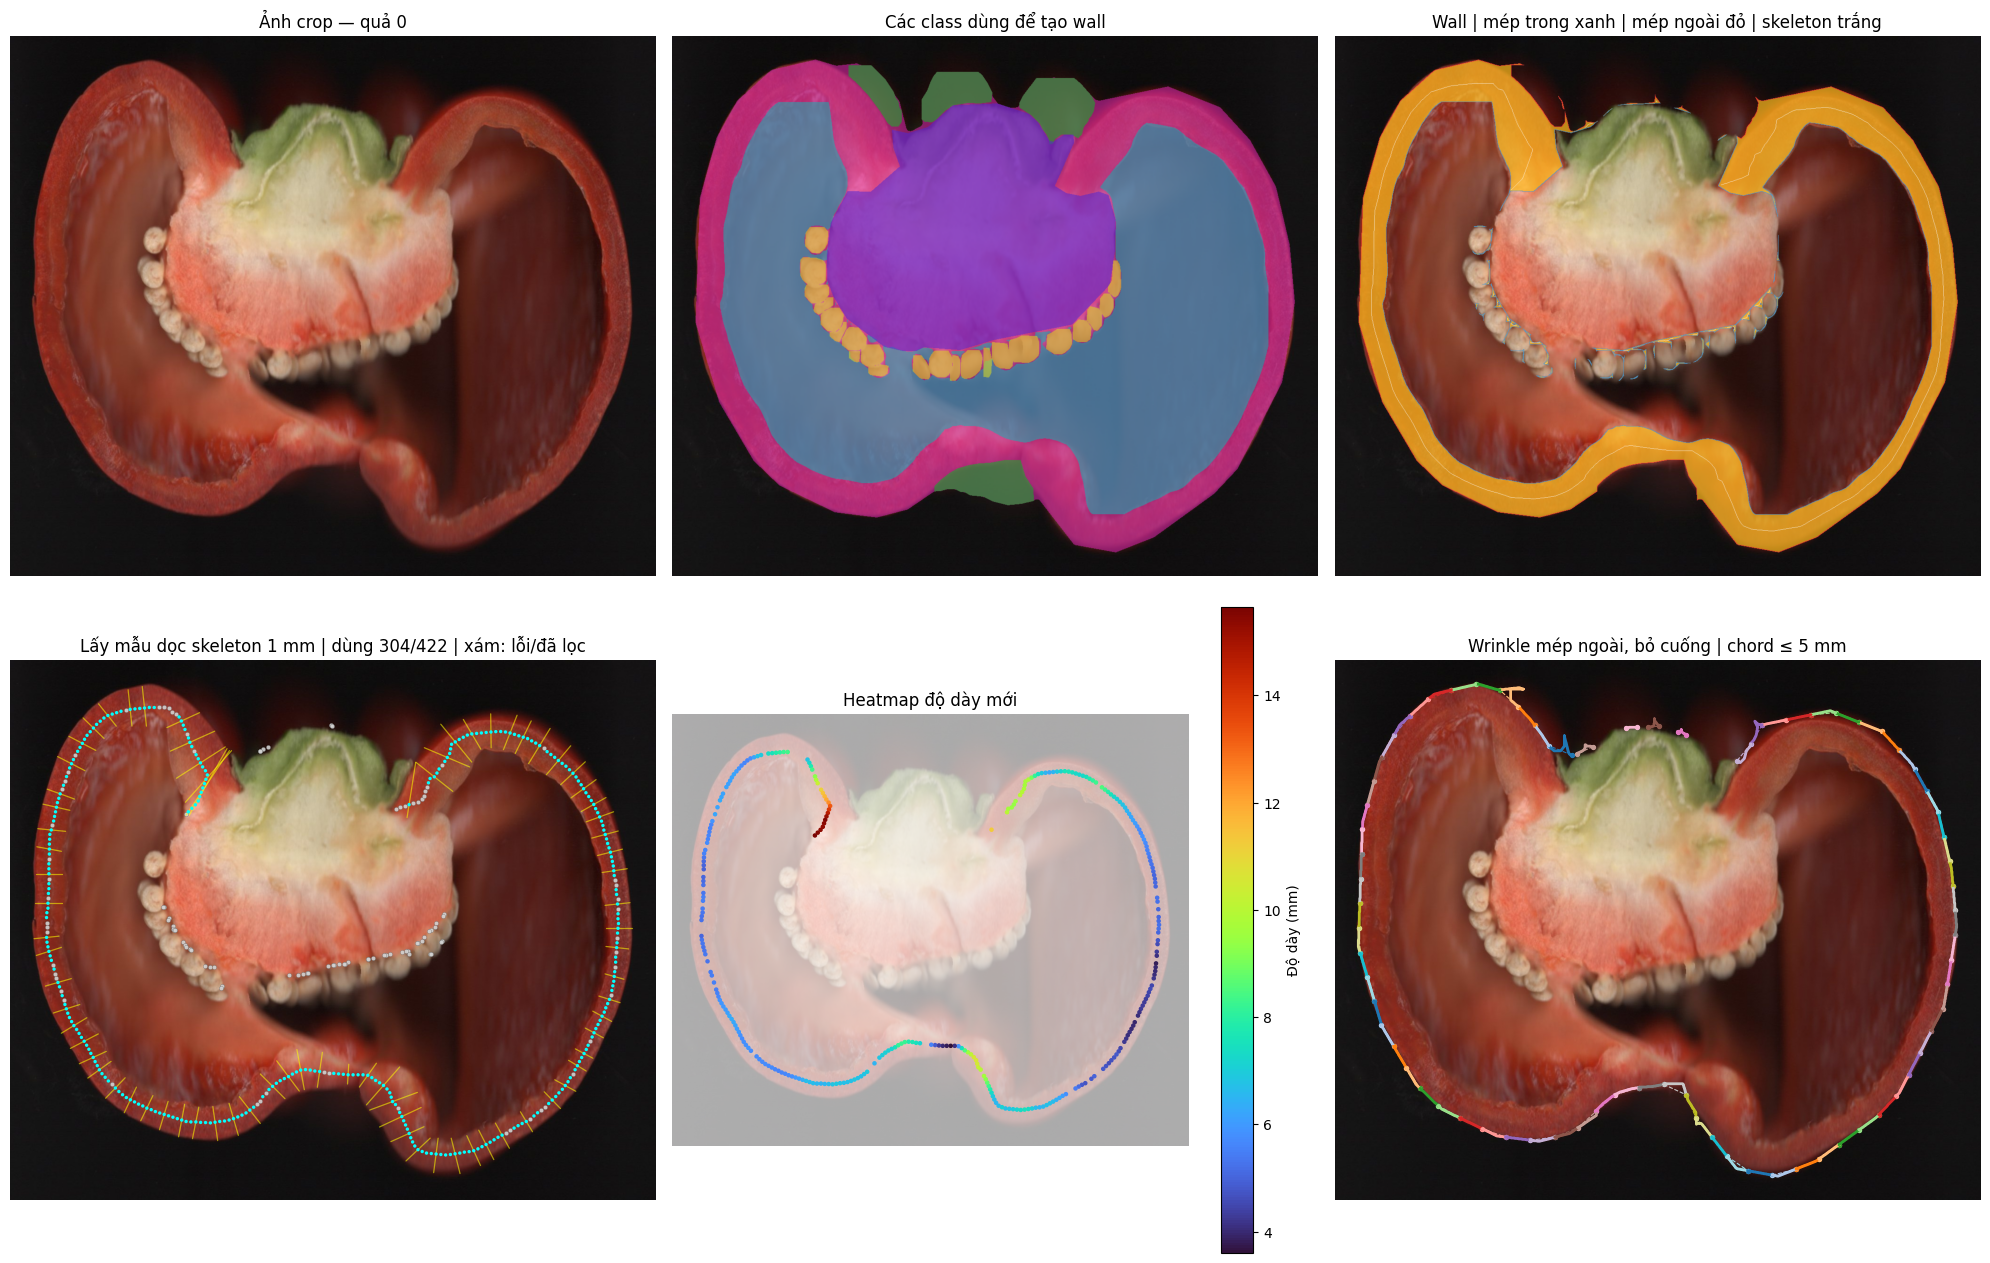

,value
scale_ratio_mm_per_px,0.094787
baseline_avg_mm,3.74548
baseline_max_mm,11.586615
new_raw_mean_mm,6.671866
new_raw_median_mm,6.142341
new_raw_min_mm,0.543688
new_raw_max_mm,16.288321
new_raw_std_mm,2.422719
raw_valid_points,368
sample_spacing_mm,1.0


,sample_id,component_id,sample_index,path_position_mm,skeleton_x,skeleton_y,is_endpoint,previous_gap_mm,is_tail_gap,filter_status,thickness_mm
0,0,1,0,0.0,818.000000,315.000000,True,NaN,False,filtered_out,10.697795
1,1,1,1,1.0,827.307359,312.000000,False,1.0,False,filtered_out,10.822080
2,2,1,2,2.0,836.614719,309.000000,False,1.0,False,filtered_out,11.078855
3,3,1,3,3.0,845.922078,306.000000,False,1.0,False,used,11.228652
4,4,1,4,4.0,855.229437,303.000000,False,1.0,False,filtered_out,11.396168
5,5,1,5,5.0,864.379572,299.620428,False,1.0,False,filtered_out,11.581174
6,6,1,6,6.0,873.015729,295.000000,False,1.0,False,filtered_out,11.434218
7,7,1,7,7.0,877.000000,287.262698,False,1.0,False,filtered_out,11.400263
8,8,1,8,8.0,878.617366,277.382634,False,1.0,False,filtered_out,11.398722
9,9,1,9,9.0,883.000000,268.647980,False,1.0,False,filtered_out,10.891245


,run_id,segment_id,start_x,start_y,end_x,end_y,arc_mm,chord_mm,curvature_ratio,curvature_excess
0,0,0,503.000000,201.000000,454.133865,181.133865,10.867422,5.0,2.173484,1.173484
1,0,1,454.133865,181.133865,424.000000,137.838222,5.286967,5.0,1.057393,0.057393
2,0,2,424.000000,137.838222,389.197757,98.197757,5.123794,5.0,1.024759,0.024759
3,0,3,389.197757,98.197757,349.908060,63.000000,11.838723,5.0,2.367745,1.367745
4,0,4,349.908060,63.000000,298.541120,51.000000,5.418572,5.0,1.083714,0.083714
5,0,5,298.541120,51.000000,247.174180,63.000000,5.340048,5.0,1.068010,0.068010
6,0,6,247.174180,63.000000,198.257831,82.742169,5.411737,5.0,1.082347,0.082347
7,0,7,198.257831,82.742169,159.011606,117.988394,5.103857,5.0,1.020771,0.020771
8,0,8,159.011606,117.988394,125.926821,159.073179,5.304315,5.0,1.060863,0.060863
9,0,9,125.926821,159.073179,99.992419,205.007581,5.372207,5.0,1.074441,0.074441


Real-image checks: PASS


In [27]:
def mask_overlay(image, masks_and_colors, alpha=0.55):
    output = image.astype(float).copy()
    for mask, color in masks_and_colors:
        selector = np.asarray(mask, dtype=bool)
        output[selector] = output[selector] * (1 - alpha) + np.asarray(color) * alpha
    return np.clip(output, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(2, 3, figsize=(20, 13))

axes[0, 0].imshow(chili.img)
axes[0, 0].set_title("Ảnh crop — quả 0")

classes_view = mask_overlay(chili.img, [
    (chili.mask_chili, (220, 40, 180)),
    (chili.mask_endocarp, (20, 180, 180)),
    (chili.mask_outer, (20, 180, 40)),
    (chili.mask_placenta, (80, 40, 210)),
    (chili.mask_seed, (220, 220, 30)),
])
axes[0, 1].imshow(classes_view)
axes[0, 1].set_title("Các class dùng để tạo wall")

edge_view = mask_overlay(chili.img, [
    (wall_data["wall"], (255, 190, 30)),
    (wall_data["inner_edge"], (30, 144, 255)),
    (wall_data["wrinkle_outer_edge"], (255, 30, 60)),
    (wall_data["stem_edge_excluded"], (120, 120, 120)),
    (wall_data["measurement_skeleton"], (255, 255, 255)),
], alpha=0.7)
axes[0, 2].imshow(edge_view)
axes[0, 2].set_title("Wall | mép trong xanh | mép ngoài đỏ | skeleton trắng")

def skeleton_branch_mask(skeleton):
    skeleton = np.asarray(skeleton, dtype=bool)
    kernel = np.ones((3, 3), dtype=int)
    neighbor_count = ndi.convolve(
        skeleton.astype(int), kernel, mode="constant", cval=0
    ) - skeleton.astype(int)
    return skeleton & (neighbor_count >= 3)

def skeleton_branch_distance(skeleton):
    """Khoảng cách (px) tới điểm nhánh (branch point) gần nhất của skeleton.
    Branch point = pixel skeleton có >= 3 hàng xóm skeleton trong lưới 3x3
    (nơi 2+ nhánh gặp nhau) — đây là vị trí ray-casting hay chọn nhầm hướng
    "mỏng nhất" giữa 2 nhánh gần như vuông góc nhau.
    """
    branch_points = skeleton_branch_mask(skeleton)
    if not np.any(branch_points):
        return np.full(skeleton.shape, np.inf)
    return ndi.distance_transform_edt(~branch_points)

def filter_clean_thickness_points(
    points,
    wall_data,
    ratio,
    k=8,
    thickness_mad_multiplier=3.0,
    angle_mad_multiplier=2.0,
    stem_margin_mm=1.5,
    branch_margin_mm=1.5,
):
    """Loại điểm đo nhiễu: quá gần cuống, quá gần điểm phân nhánh skeleton,
    hoặc lệch bất thường (thickness/góc) so với các hàng xóm gần nhất.
    stem_margin_mm/branch_margin_mm quy đổi theo ratio để không bị "ăn"
    quá đà trên quả nhỏ/mảnh — dùng mm thay vì px cố định để ổn định
    qua nhiều ảnh có ratio khác nhau."""
    if len(points) < 3:
        return points.copy().reset_index(drop=True)

    stem_margin_px = stem_margin_mm / ratio
    branch_margin_px = branch_margin_mm / ratio

    stem_distance = ndi.distance_transform_edt(~wall_data["stem_exclusion"])
    near_stem = bilinear_many(
        stem_distance, points.skeleton_x.to_numpy(), points.skeleton_y.to_numpy()
    ) < stem_margin_px

    branch_distance = skeleton_branch_distance(wall_data["measurement_skeleton"])
    near_branch = bilinear_many(
        branch_distance, points.skeleton_x.to_numpy(), points.skeleton_y.to_numpy(), np.inf
    ) < branch_margin_px

    xy = points[["skeleton_x", "skeleton_y"]].to_numpy()
    tree = cKDTree(xy)
    neighbor_k = min(max(3, k + 1), len(xy))
    _, neighbor_idx = tree.query(xy, k=neighbor_k)
    neighbor_idx = np.asarray(neighbor_idx)[:, 1:]  # bỏ chính điểm đó (cột 0)

    thickness = points.thickness_mm.to_numpy()
    local_median = np.median(thickness[neighbor_idx], axis=1)
    local_mad = np.maximum(
        np.median(np.abs(thickness[neighbor_idx] - local_median[:, None]), axis=1),
        0.05,  # sàn 0,05 mm tránh chia cho MAD gần 0
    )
    thickness_deviation = np.abs(thickness - local_median) / local_mad
    is_thickness_outlier = thickness_deviation > thickness_mad_multiplier

    angles = points.angle_deg.to_numpy()
    neighbor_angles = angles[neighbor_idx]
    # Góc lát cắt là axial data: 0° và 180° biểu diễn cùng một hướng.
    doubled = np.deg2rad(2.0 * neighbor_angles)
    local_angle = (
        0.5 * np.rad2deg(np.arctan2(np.mean(np.sin(doubled), axis=1), np.mean(np.cos(doubled), axis=1)))
    ) % 180.0
    angle_deviation = np.abs(angles - local_angle)
    angle_deviation = np.minimum(angle_deviation, 180.0 - angle_deviation)
    neighbor_deviation = np.abs(neighbor_angles - local_angle[:, None])
    neighbor_deviation = np.minimum(neighbor_deviation, 180.0 - neighbor_deviation)
    local_angle_median = np.median(neighbor_deviation, axis=1)
    local_angle_mad = np.maximum(
        np.median(np.abs(neighbor_deviation - local_angle_median[:, None]), axis=1), 1.0
    )
    is_angle_outlier = angle_deviation > (
        local_angle_median + angle_mad_multiplier * local_angle_mad
    )

    clean = points[
        (~near_stem) & (~near_branch) & (~is_thickness_outlier) & (~is_angle_outlier)
    ].reset_index(drop=True)
    return clean

thickness_points_clean = filter_clean_thickness_points(
    thickness_points, wall_data, ratio, stem_margin_mm=1.5, branch_margin_mm=2.5
)
minimum_clean_count = max(20, int(0.30 * len(thickness_points)))
if len(thickness_points_clean) >= minimum_clean_count:
    thickness_points_used = thickness_points_clean
    thickness_filter_mode = "clean"
else:
    # Với mask quá nhỏ/xấu, ưu tiên có kết quả và gắn cờ thay vì trả bảng rỗng.
    thickness_points_used = thickness_points.reset_index(drop=True)
    thickness_filter_mode = "fallback_raw"

thickness_samples_display = thickness_samples.copy()
thickness_samples_display["filter_status"] = thickness_samples_display["measurement_status"]
measured_mask = thickness_samples_display.measurement_status == "measured"
thickness_samples_display.loc[measured_mask, "filter_status"] = "filtered_out"
used_ids = set(thickness_points_used.sample_id.astype(int))
thickness_samples_display.loc[
    thickness_samples_display.sample_id.astype(int).isin(used_ids), "filter_status"
] = "used"
filtered_point_count = int((thickness_samples_display.filter_status == "filtered_out").sum())

thickness_summary = {
    **thickness_raw_summary,
    "new_mean_mm": thickness_points_used["thickness_mm"].mean(),
    "new_median_mm": thickness_points_used["thickness_mm"].median(),
    "new_min_mm": thickness_points_used["thickness_mm"].min(),
    "new_max_mm": thickness_points_used["thickness_mm"].max(),
    "new_std_mm": thickness_points_used["thickness_mm"].std(ddof=0),
    "used_points": len(thickness_points_used),
    "filtered_points": filtered_point_count,
    "ray_failed_points": int((thickness_samples_display.filter_status == "ray_failed").sum()),
    "filter_mode": thickness_filter_mode,
}

axes[1, 0].imshow(chili.img)
rejected = thickness_samples_display[thickness_samples_display.filter_status != "used"]
axes[1, 0].scatter(
    rejected.skeleton_x, rejected.skeleton_y, s=9, c="lightgray",
    edgecolors="dimgray", linewidths=0.25, alpha=0.9, zorder=1,
)
sample_count = min(80, len(thickness_points_used))
sample_indices = np.linspace(0, len(thickness_points_used) - 1, sample_count, dtype=int)
sampled = thickness_points_used.iloc[sample_indices]
for _, row in sampled.iterrows():
    axes[1, 0].plot(
        [row.outer_x, row.inner_x],
        [row.outer_y, row.inner_y],
        color="yellow",
        linewidth=0.9,
        alpha=0.55,
        solid_capstyle="round",
        zorder=2,
    )
axes[1, 0].scatter(
    thickness_points_used.skeleton_x,
    thickness_points_used.skeleton_y,
    s=6,
    c="cyan",
    edgecolors="none",
    zorder=3,
)
axes[1, 0].set_title(
    f"Lấy mẫu dọc skeleton 1 mm | dùng {len(thickness_points_used)}/{len(thickness_samples)} | xám: lỗi/đã lọc"
)

axes[1, 1].imshow(chili.img, alpha=0.35)
scatter = axes[1, 1].scatter(
    thickness_points_used.skeleton_x,
    thickness_points_used.skeleton_y,
    c=thickness_points_used.thickness_mm,
    s=5,
    cmap="turbo",
)
fig.colorbar(scatter, ax=axes[1, 1], label="Độ dày (mm)")
axes[1, 1].set_title("Heatmap độ dày mới")

axes[1, 2].imshow(chili.img)
colors = plt.cm.tab20(np.linspace(0, 1, 20))
global_segment_index = 0
for points, cumulative, segments in wrinkle_geometries:
    for segment in segments:
        section = slice_polyline(
            points, cumulative, segment["start_s"], segment["end_s"]
        )
        color = colors[global_segment_index % len(colors)]
        axes[1, 2].plot(section[:, 0], section[:, 1], color=color, linewidth=2.0)
        axes[1, 2].plot(
            [segment["start"][0], segment["end"][0]],
            [segment["start"][1], segment["end"][1]],
            color=color,
            linewidth=0.8,
            linestyle="--",
        )
        axes[1, 2].scatter(
            [segment["start"][0], segment["end"][0]],
            [segment["start"][1], segment["end"][1]],
            color=[color],
            s=8,
        )
        global_segment_index += 1
axes[1, 2].set_title(f"Wrinkle mép ngoài, bỏ cuống | chord ≤ {WRINKLE_SEGMENT_THRESHOLD_MM:g} mm")

for axis in axes.flat:
    axis.axis("off")
plt.tight_layout()
plt.show()

comparison = pd.DataFrame([
    {
        "scale_ratio_mm_per_px": ratio,
        **thickness_summary,
        **wrinkle_summary,
    }
])
display(comparison.T.rename(columns={0: "value"}))
display(thickness_samples_display[[
    "sample_id", "component_id", "sample_index", "path_position_mm",
    "skeleton_x", "skeleton_y", "is_endpoint", "previous_gap_mm",
    "is_tail_gap", "filter_status", "thickness_mm",
]].head(30))
display(wrinkle_segments.head(20))

assert thickness_coverage > 0
assert spacing_error_max_mm <= 0.01
assert np.isfinite(comparison.select_dtypes(include=[np.number]).to_numpy()).all()
print("Real-image checks: PASS")